# 02 EDA — Audiencias Realizadas, Familia (PJUD, C.A. Valparaíso, 2015–2025)
### Taller de Ciencia de Datos · Equipo EMCR

**Objetivo:** convertir el dataset limpio del notebook *01 ETL* en preguntas, evidencia y hallazgos.
Seguimos la estructura de la Clase 4: pregunta → reconocimiento → descriptivo → univariado → bivariado → correlación → grupos → multivariado → tiempo → hallazgos → siguientes pasos.

**Insumo:** `data/processed/audiencias_preparadas_modelo.parquet` (466.178 audiencias × 36 columnas, 0 nulos), generado al final del notebook 01.

> Idea central: **EDA ≠ hacer gráficos. EDA = investigar los datos antes de modelar.**

## 0. Pregunta de trabajo

El notebook 01 dejó 16 variables derivadas pensadas para un estudio de abogados de Familia. Cada una abre una pregunta distinta. Estas son cinco candidatas para elegir el hilo conductor:

| # | Pregunta | Y (variable objetivo) | X principales | Valor para el estudio |
|---|----------|----------------------|---------------|-----------------------|
| **P1** | ¿Qué variables se asocian con la **espera** para una audiencia y cómo cambia según tribunal, materia y época? | `PLAZO_AGENDAMIENTO` | tribunal, macro materia, tipo de audiencia, época, videoconferencia, calendario | Dar fechas realistas al cliente y comparar tribunales |
| **P2** | ¿De qué depende la **duración** de una audiencia y cuándo se **frustra**? | `DURACION_MINUTOS`, `FLG_AUDIENCIA_FRUSTRADA` | tipo de audiencia, materia, bloque horario, tribunal | Agendar bloques de trabajo y estimar horas facturables |
| **P3** | ¿Qué hace que una causa requiera **muchas audiencias**? | `TOTAL_AUDIENCIAS_CAUSA` | materia, tribunal, tipo de la primera audiencia, año | Estimar carga y costo total de una causa |
| **P4** | ¿Cómo cambió el sistema con la **virtualidad** (pandemia y régimen híbrido)? | espera, duración y modalidad por época | `EPOCA_NORMATIVA`, `VIDEOCONFERENCIA`, año | Decidir cuándo pedir audiencia remota |
| **P5** | ¿Dónde y cuándo se **concentra la carga** de audiencias? | conteo de audiencias | tribunal, mes, día de semana, bloque horario | Planificar la agenda del estudio |

**Pregunta que usa este notebook por defecto: P1** (espera). La elegimos porque `PLAZO_AGENDAMIENTO` está completa y depurada, el gráfico por tribunal compara eficiencia entre jurisdicciones (la meta del proyecto) y alimenta directamente un modelo predictivo. Si el equipo prefiere otra, basta cambiar la variable `Y` de la sección 1 y revisar las secciones 7 a 10, que son las que dependen de ella.

- **Y:** `PLAZO_AGENDAMIENTO` (días entre la programación y la realización de la audiencia).
- **X:** `TRIBUNAL`, `MACRO_MATERIA`, `TIPO_AUDIENCIA`, `EPOCA_NORMATIVA`, `VIDEOCONFERENCIA`, `DIA_SEMANA_AUDIENCIA`, `ORDEN_AUDIENCIA_CAUSA`.
- **T:** `FECHA_AUDIENCIA` / `ANO_AUDIENCIA`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

COLOR = '#2E6F95'      # color base de todos los gráficos
COLOR2 = '#C2571A'     # color de contraste (medias, modalidad remota, hitos)

DATA = Path('../data/processed/audiencias_preparadas_modelo.parquet')
try:
    df = pd.read_parquet(DATA, engine='pyarrow')
except ImportError:
    # Si pyarrow no carga (p. ej. bloqueado por una política de Windows) se usa DuckDB.
    # No usar fastparquet: con este archivo lee mal columnas de texto (RIT, ID_CAUSA_RIT quedan con nulos).
    import duckdb
    df = duckdb.sql(f"select * from read_parquet('{DATA.as_posix()}')").df()

# Los enteros con soporte de nulos (Int64) dan problemas en seaborn: pasamos a float
for c in ['PLAZO_AGENDAMIENTO', 'ANO_AUDIENCIA', 'TOTAL_AUDIENCIAS', 'COD_TRIBUNAL', 'COD_CORTE']:
    df[c] = df[c].astype('float64')

# Etiquetas cortas de tribunal para que los gráficos se lean
df['TRIBUNAL_CORTO'] = (df['TRIBUNAL']
                        .str.replace('JUZGADO DE LETRAS Y GARANTIA DE', 'LETRAS Y GARANTIA', regex=False)
                        .str.replace('JUZGADO DE FAMILIA DE', 'FAMILIA', regex=False)
                        .str.title())

Y = 'PLAZO_AGENDAMIENTO'   # <- cambiar aquí si el equipo elige otra pregunta
df.head()

,COD_CORTE,CORTE,COD_TRIBUNAL,TRIBUNAL,RIT,TIPO_PROCEDIMIENTO,TIPO_AUDIENCIA,FECHA_INGRESO,FECHA_PROGRAMACION,FECHA_AUDIENCIA,PLAZO_AGENDAMIENTO,HORA_INICIO,HORA_FIN,ANO_AUDIENCIA,COMPETENCIA,TOTAL_AUDIENCIAS,VIDEOCONFERENCIA,ANO_PROCESO,FLG_CRUCE_2023,ID_CAUSA_RIT,DIA_SEMANA_AUDIENCIA,MES_AUDIENCIA,TRIMESTRE_AUDIENCIA,DURACION_MINUTOS,BLOQUE_HORARIO,TRAMO_DURACION,FLG_AUDIENCIA_FRUSTRADA,DIAS_TRAMITACION_PREVIA,DIAS_DESPACHO_AGENDAMIENTO,TRAMO_AGENDAMIENTO,ORDEN_AUDIENCIA_CAUSA,TOTAL_AUDIENCIAS_CAUSA,ES_AUDIENCIA_INICIAL,ES_CONTINUACION,MACRO_MATERIA,EPOCA_NORMATIVA,TRIBUNAL_CORTO
0,30.00,C.A. DE VALPARAISO,103.00,JUZGADO DE LETRAS Y GARANTIA DE ISLA DE PASCUA,A-1-2016,ADOPCION,AUDIENCIA PREPARATORIA,2016-11-25,2016-12-10,2017-01-12,29.00,12:35:00,13:20:00,"2,017.00",FAMILIA,1.00,False,2017,False,103-A-1-2016,Jueves,Enero,Q1,45.00,Mediodía (12:00-13:59),3. Extendida (31-60 min),False,48,15,3. Estándar Legal (16-30 días),1,3,True,False,Actos No Contenciosos y Voluntarios,Pre-Pandemia (Presencial),Letras Y Garantia Isla De Pascua
1,30.00,C.A. DE VALPARAISO,103.00,JUZGADO DE LETRAS Y GARANTIA DE ISLA DE PASCUA,A-1-2016,ADOPCION,AUDIENCIA DE JUICIO,2016-11-25,2017-03-03,2017-04-04,28.00,13:05:00,13:10:00,"2,017.00",FAMILIA,1.00,False,2017,False,103-A-1-2016,Martes,Abril,Q2,5.00,Mediodía (12:00-13:59),1. Breve (1-15 min),False,130,98,3. Estándar Legal (16-30 días),2,3,False,False,Actos No Contenciosos y Voluntarios,Pre-Pandemia (Presencial),Letras Y Garantia Isla De Pascua
2,30.00,C.A. DE VALPARAISO,103.00,JUZGADO DE LETRAS Y GARANTIA DE ISLA DE PASCUA,A-1-2016,ADOPCION,AUDIENCIA,2016-11-25,2017-04-04,2017-04-07,4.00,10:00:00,10:20:00,"2,017.00",FAMILIA,1.00,False,2017,False,103-A-1-2016,Viernes,Abril,Q2,20.00,Mañana Central (10:00-11:59),2. Estándar (16-30 min),False,133,130,2. Rápido (1-15 días),3,3,False,False,Actos No Contenciosos y Voluntarios,Pre-Pandemia (Presencial),Letras Y Garantia Isla De Pascua
3,30.00,C.A. DE VALPARAISO,103.00,JUZGADO DE LETRAS Y GARANTIA DE ISLA DE PASCUA,A-1-2017,ADOPCION,AUDIENCIA PREPARATORIA,2017-07-04,2017-11-17,2017-12-14,24.00,12:32:00,12:53:00,"2,017.00",FAMILIA,1.00,False,2017,False,103-A-1-2017,Jueves,Diciembre,Q4,21.00,Mediodía (12:00-13:59),2. Estándar (16-30 min),False,163,136,3. Estándar Legal (16-30 días),1,1,True,False,Actos No Contenciosos y Voluntarios,Pre-Pandemia (Presencial),Letras Y Garantia Isla De Pascua
4,30.00,C.A. DE VALPARAISO,103.00,JUZGADO DE LETRAS Y GARANTIA DE ISLA DE PASCUA,A-1-2021,ADOPCION,AUDIENCIA PREPARATORIA,2021-09-14,2021-12-01,2021-12-21,16.00,10:16:00,10:44:00,"2,021.00",FAMILIA,1.00,True,2021,False,103-A-1-2021,Martes,Diciembre,Q4,28.00,Mañana Central (10:00-11:59),2. Estándar (16-30 min),False,98,78,3. Estándar Legal (16-30 días),1,3,True,False,Actos No Contenciosos y Voluntarios,Emergencia Sanitaria (Ley 21.226),Letras Y Garantia Isla De Pascua


## 1. Reconocimiento del dataset
Antes de graficar verificamos que sabemos **qué representa cada fila y cada variable**. El notebook 01 ya hizo la auditoría completa, aquí solo confirmamos que el parquet llegó como se esperaba.

In [2]:
print('Dimensiones:', df.shape)
print('Unidad de análisis: una audiencia realizada')
print('Causas únicas (ID_CAUSA_RIT):', f"{df['ID_CAUSA_RIT'].nunique():,}")
print('Tribunales:', df['COD_TRIBUNAL'].nunique())
print('Rango de fechas de audiencia:', df['FECHA_AUDIENCIA'].min().date(), 'a', df['FECHA_AUDIENCIA'].max().date())
print('Nulos totales:', int(df.isna().sum().sum()))
print()
tipos = df.dtypes.astype(str).value_counts().rename('columnas').to_frame()
tipos

Dimensiones: (466178, 37)
Unidad de análisis: una audiencia realizada
Causas únicas (ID_CAUSA_RIT): 280,795
Tribunales: 15
Rango de fechas de audiencia: 2015-01-02 a 2025-12-31
Nulos totales: 0



,columnas
str,18
float64,6
bool,5
datetime64[ns],3
int64,3
int16,2


### Pregunta de interpretación
- **Unidad de análisis:** una audiencia realizada. Una causa (`ID_CAUSA_RIT`) tiene varias filas, así que las filas **no son independientes**. Esto importa al modelar (se debe separar por causa o por tiempo, nunca al azar fila a fila).
- **Numéricas:** plazo, duración, días de tramitación, orden y total de audiencias por causa.
- **Categóricas:** tribunal, materia, tipo de audiencia, época, bloque horario, día de la semana.
- **Y:** `PLAZO_AGENDAMIENTO`. **X posibles:** el resto de las variables de contexto.
- **Ojo con fugas de información:** `DIAS_TRAMITACION_PREVIA` y `DIAS_DESPACHO_AGENDAMIENTO` se calculan con fechas que incluyen el plazo, así que **no** pueden usarse para predecirlo (lo vemos en la sección 6).

## 2. Estadística descriptiva: posición y dispersión de Y
**Por qué:** la media y la mediana de la espera dicen si "el trámite típico" es lo mismo que "el trámite promedio". En plazos judiciales la distribución suele tener cola larga.

In [3]:
y = df[Y]
resumen = pd.Series({
    'media': y.mean(), 'mediana': y.median(), 'desv_std': y.std(),
    'min': y.min(), 'Q1': y.quantile(.25), 'Q3': y.quantile(.75),
    'P90': y.quantile(.90), 'P95': y.quantile(.95), 'P99': y.quantile(.99),
    'max': y.max(), 'IQR': y.quantile(.75) - y.quantile(.25), 'skewness': y.skew()
})
resumen.round(2)

media       31.39
mediana     26.00
desv_std    25.01
min          0.00
Q1          12.00
Q3          43.00
P90         64.00
P95         77.00
P99        117.00
max        339.00
IQR         31.00
skewness     1.70
dtype: float64

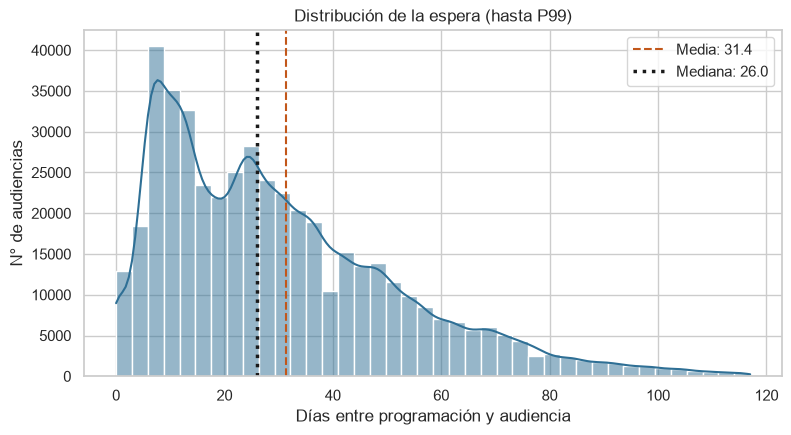

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
lim = y.quantile(.99)
sns.histplot(y[y <= lim], bins=40, kde=True, ax=ax, color=COLOR)
ax.axvline(y.mean(), ls='--', color=COLOR2, label=f'Media: {y.mean():.1f}')
ax.axvline(y.median(), ls=':', lw=2.5, color='k', label=f'Mediana: {y.median():.1f}')
ax.set(title='Distribución de la espera (hasta P99)', xlabel='Días entre programación y audiencia', ylabel='N° de audiencias')
ax.legend()
plt.show()

**Por qué este gráfico (equivale al histograma de `monto_venta` de la Clase 4):** muestra la forma de Y y la distancia entre media y mediana. Cortamos en el P99 para que unos pocos casos extremos no aplasten el resto del eje.
**Discusión:** si la media supera a la mediana, hay cola a la derecha y la mediana representa mejor la "espera típica". Para el cliente conviene informar **rangos** (por ejemplo P25 a P75) y no un solo promedio.

## 3. EDA univariado: variables numéricas
**Por qué:** antes de relacionar variables hay que conocer la escala y los extremos de cada una. Elegimos las cuatro numéricas con más sentido de negocio: espera, duración, días de tramitación total y audiencias por causa. Se usa histograma + boxplot, igual que en la clase.

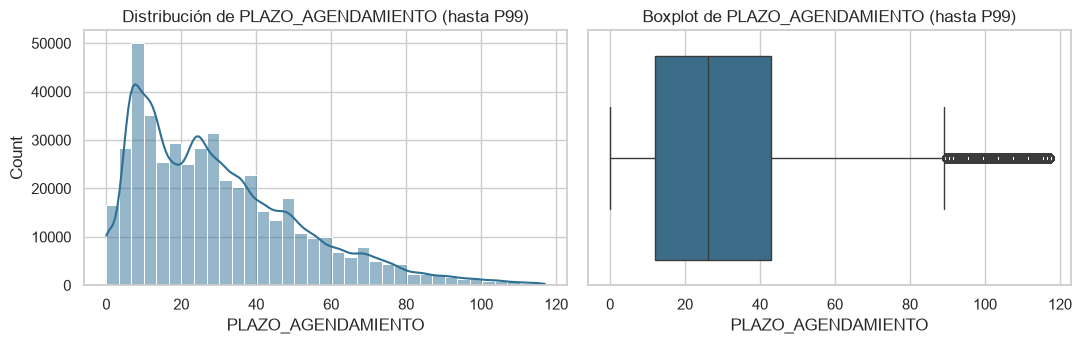

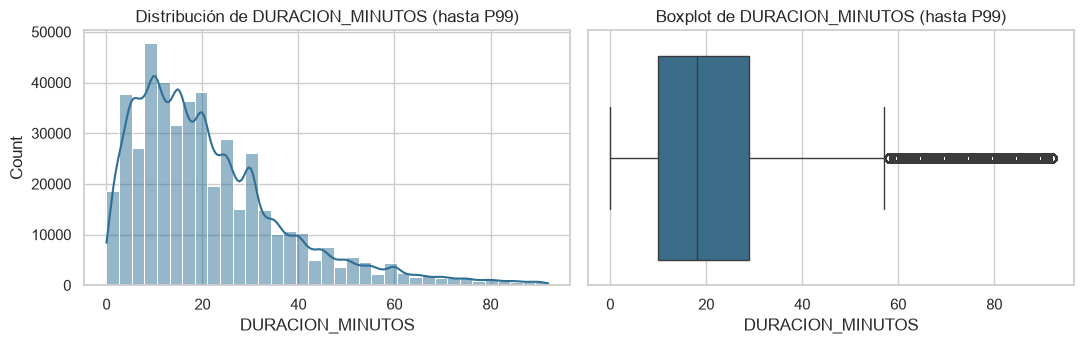

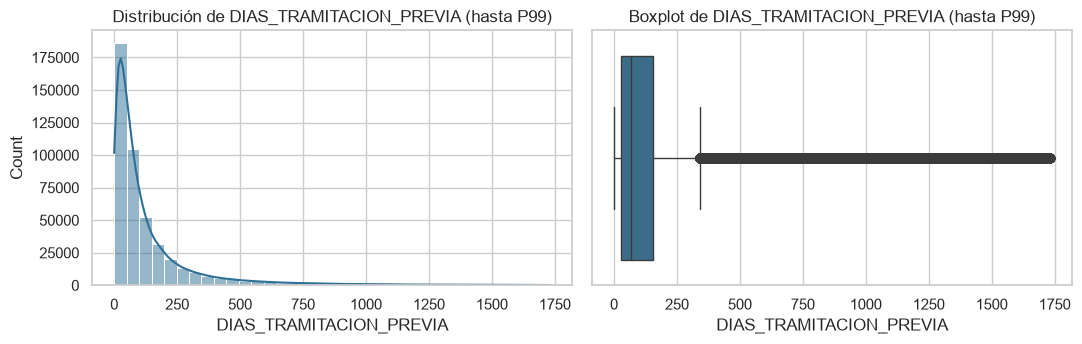

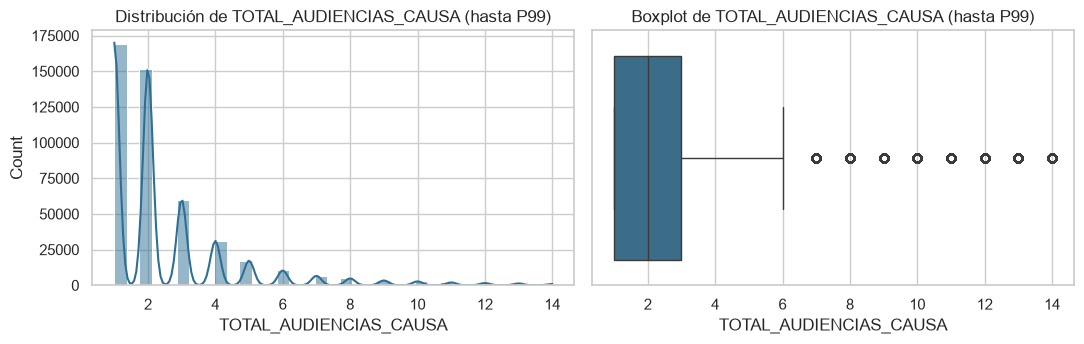

In [5]:
variables = ['PLAZO_AGENDAMIENTO', 'DURACION_MINUTOS', 'DIAS_TRAMITACION_PREVIA', 'TOTAL_AUDIENCIAS_CAUSA']
for col in variables:
    s = df[col].astype(float)
    lim = s.quantile(.99)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    sns.histplot(s[s <= lim], bins=35, kde=True, ax=axes[0], color=COLOR)
    sns.boxplot(x=s[s <= lim], ax=axes[1], color=COLOR)
    axes[0].set_title(f'Distribución de {col} (hasta P99)')
    axes[1].set_title(f'Boxplot de {col} (hasta P99)')
    plt.tight_layout()
    plt.show()

### Outliers como pregunta, no como sentencia
**Por qué:** el notebook 01 ya decidió conservar los valores extremos de plazo. Aquí solo los **detectamos** con la regla de 1,5·IQR y miramos dónde se concentran, para decidir después si importan al modelo.

In [6]:
q1, q3 = y.quantile([.25, .75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
out = df[df[Y] > lim_sup]
print(f'Límite superior IQR: {lim_sup:.0f} días')
print(f'Observaciones marcadas: {len(out):,} ({len(out)/len(df):.1%})')
print()
print('¿Dónde se concentran los plazos extremos?')
(out['TRIBUNAL_CORTO'].value_counts(normalize=True).head(5).mul(100).round(1).rename('% de los outliers').to_frame())

Límite superior IQR: 90 días
Observaciones marcadas: 13,428 (2.9%)

¿Dónde se concentran los plazos extremos?


,% de los outliers
TRIBUNAL_CORTO,
Familia Vina Del Mar,26.90
Familia Quillota,14.00
Familia Valparaiso,12.80
Letras Y Garantia Quintero,11.30
Familia La Ligua,10.10


**Lectura:** si los extremos se concentran en pocos tribunales, no son "ruido": son una señal de congestión y deben quedarse en el análisis.

## 4. EDA univariado: variables categóricas
**Por qué:** el volumen por categoría decide qué comparaciones son confiables. Una categoría con pocas audiencias da medianas inestables. Se usan gráficos de barras de frecuencia, como en la clase.

,n,pct
MACRO_MATERIA,,
Litigación Contenciosa,209100,44.90
Medidas Cautelares y Vulnerabilidad,207328,44.50
Ejecución y Alimentos (Cumplimiento),42711,9.20
Actos No Contenciosos y Voluntarios,7017,1.50
Otros Procedimientos,22,0.00


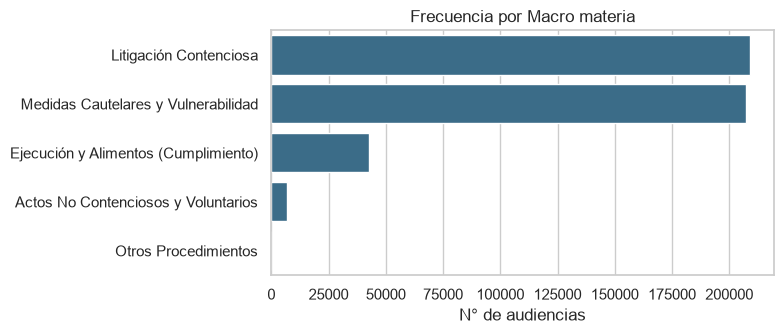

,n,pct
EPOCA_NORMATIVA,,
Pre-Pandemia (Presencial),225891,48.50
Régimen Permanente Híbrido (Ley 21.394),142638,30.60
Emergencia Sanitaria (Ley 21.226),97649,20.90


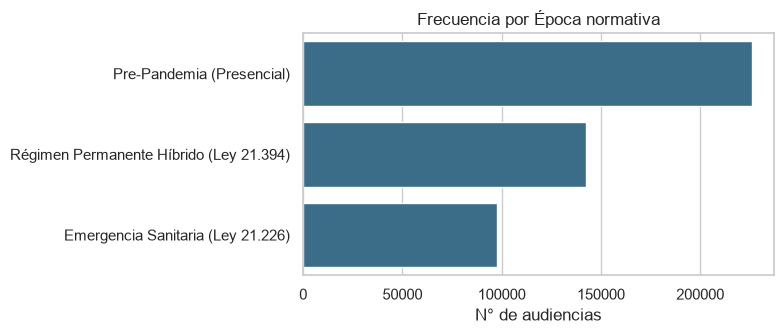

,n,pct
BLOQUE_HORARIO,,
Mañana Central (10:00-11:59),188063,40.30
Mediodía (12:00-13:59),138373,29.70
Mañana Temprano (08:00-09:59),135016,29.00
Tarde (14:00-16:59),4705,1.00
Vespertino / Turno (>= 17:00),21,0.00


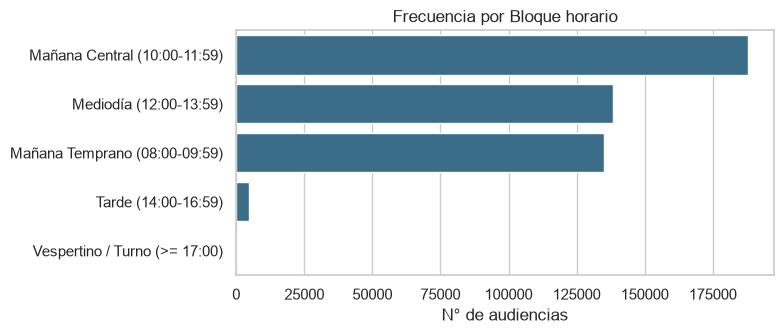

,n,pct
DIA_SEMANA_AUDIENCIA,,
Miércoles,98902,21.20
Martes,97331,20.90
Jueves,95345,20.50
Lunes,95101,20.40
Viernes,79311,17.00
Sábado,184,0.00
Domingo,4,0.00


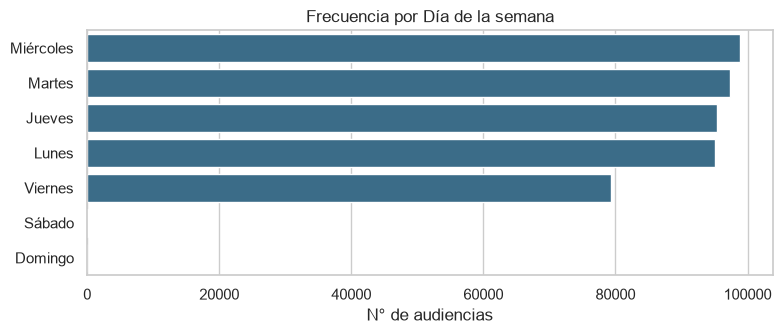

In [7]:
cats = {'MACRO_MATERIA': 'Macro materia', 'EPOCA_NORMATIVA': 'Época normativa',
        'BLOQUE_HORARIO': 'Bloque horario', 'DIA_SEMANA_AUDIENCIA': 'Día de la semana'}
for col, nombre in cats.items():
    tabla = df[col].value_counts(dropna=False).to_frame('n').assign(pct=lambda x: 100 * x['n'] / len(df)).round(1)
    display(tabla)
    plt.figure(figsize=(8, 3.5))
    sns.countplot(data=df, y=col, order=df[col].value_counts().index, color=COLOR)
    plt.title(f'Frecuencia por {nombre}')
    plt.xlabel('N° de audiencias'); plt.ylabel('')
    plt.tight_layout(); plt.show()

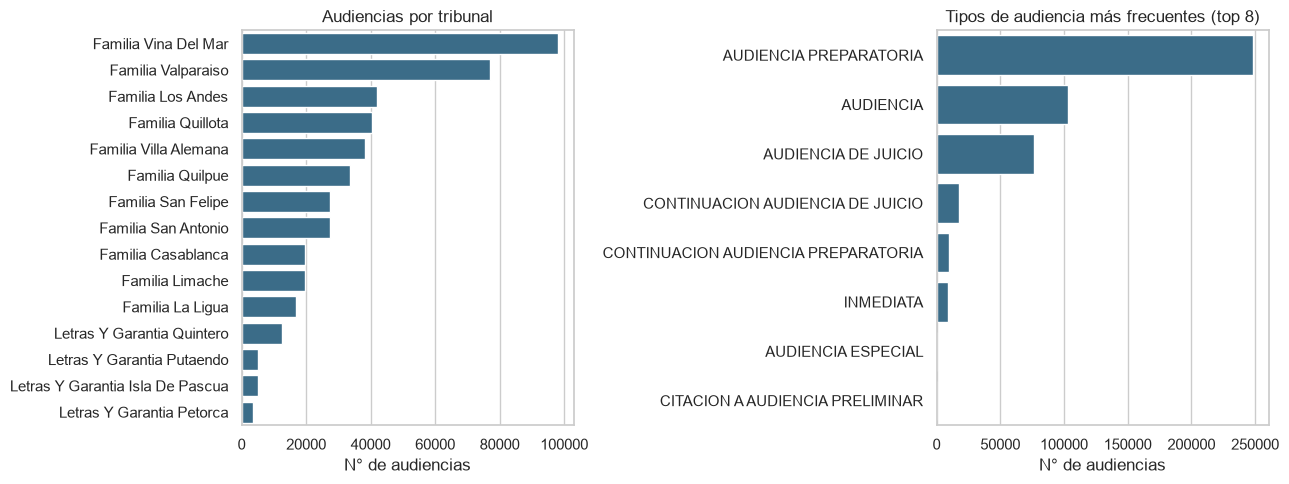

Tipos de audiencia en total: 12


In [8]:
# Tribunales y tipos de audiencia: muchos niveles, mostramos los principales
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
orden_t = df['TRIBUNAL_CORTO'].value_counts().index
sns.countplot(data=df, y='TRIBUNAL_CORTO', order=orden_t, color=COLOR, ax=axes[0])
axes[0].set(title='Audiencias por tribunal', xlabel='N° de audiencias', ylabel='')
top_ta = df['TIPO_AUDIENCIA'].value_counts().head(8).index
sns.countplot(data=df[df['TIPO_AUDIENCIA'].isin(top_ta)], y='TIPO_AUDIENCIA', order=top_ta, color=COLOR, ax=axes[1])
axes[1].set(title='Tipos de audiencia más frecuentes (top 8)', xlabel='N° de audiencias', ylabel='')
plt.tight_layout(); plt.show()
print('Tipos de audiencia en total:', df['TIPO_AUDIENCIA'].nunique())

**Por qué estos gráficos:** muestran el desbalance. Pocos tribunales concentran gran parte del volumen y unos pocos tipos de audiencia dominan. Tribunales pequeños (por ejemplo Isla de Pascua o Putaendo) tendrán medianas con mucho menos respaldo, y habrá que tratarlas con cautela en el modelo.

## 5. EDA bivariado: numérica vs numérica
**Por qué:** un scatterplot revela tendencia, dispersión y grupos. Con 466 mil puntos un gráfico directo es ilegible, así que usamos una **muestra aleatoria** y transparencia, igual que hace la clase con 1.000 puntos.
Cruzamos la espera con la duración de la audiencia, porque queremos saber si las audiencias que esperan más también duran más (congestión que se traspasa a la sala).

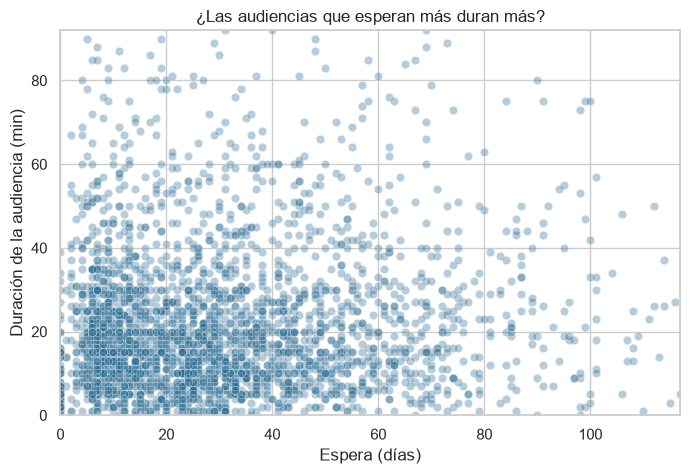

In [9]:
sample = df.sample(min(3000, len(df)), random_state=42)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=sample, x='PLAZO_AGENDAMIENTO', y='DURACION_MINUTOS', alpha=.35, ax=ax, color=COLOR)
ax.set_xlim(0, df[Y].quantile(.99)); ax.set_ylim(0, df['DURACION_MINUTOS'].quantile(.99))
ax.set_title('¿Las audiencias que esperan más duran más?')
ax.set(xlabel='Espera (días)', ylabel='Duración de la audiencia (min)')
plt.show()

**Lectura:** una nube sin pendiente indica que espera y duración son independientes. Las bandas horizontales corresponden a duraciones "redondas" (15, 30, 45, 60 min) que registran los tribunales, no a una relación entre las variables.

## 6. Correlación: Pearson y Spearman
**Por qué:**
- **Pearson** mide asociación lineal. **Spearman** mide asociación monótona por rangos y resiste mejor los extremos, que aquí abundan.
- Ponemos ambas lado a lado porque, con plazos de cola larga, pueden dar valores distintos.
- Una correlación baja **no** garantiza ausencia de relación, y correlación **no** implica causalidad.
- Esta sección también sirve para **detectar fugas**: si una variable correlaciona casi perfecto con Y por cómo se construyó, no sirve para predecir.

In [10]:
cols = ['PLAZO_AGENDAMIENTO', 'DURACION_MINUTOS', 'DIAS_TRAMITACION_PREVIA', 'DIAS_DESPACHO_AGENDAMIENTO',
        'ORDEN_AUDIENCIA_CAUSA', 'TOTAL_AUDIENCIAS_CAUSA', 'ANO_AUDIENCIA']
num = df[cols].astype(float).copy()
num['VIDEOCONFERENCIA'] = df['VIDEOCONFERENCIA'].astype(int)
num['FRUSTRADA'] = df['FLG_AUDIENCIA_FRUSTRADA'].astype(int)

pearson = num.corr(method='pearson')
spearman = num.corr(method='spearman')

comparacion = pd.DataFrame({'Pearson_con_Y': pearson[Y], 'Spearman_con_Y': spearman[Y]}) \
                .sort_values('Pearson_con_Y', key=abs, ascending=False)
comparacion.round(3)

,Pearson_con_Y,Spearman_con_Y
PLAZO_AGENDAMIENTO,1.00,1.00
ANO_AUDIENCIA,0.27,0.23
VIDEOCONFERENCIA,0.24,0.18
DIAS_TRAMITACION_PREVIA,0.12,0.54
ORDEN_AUDIENCIA_CAUSA,0.07,0.19
DURACION_MINUTOS,0.07,0.04
TOTAL_AUDIENCIAS_CAUSA,0.04,0.14
DIAS_DESPACHO_AGENDAMIENTO,0.03,0.28
FRUSTRADA,-0.00,-0.00


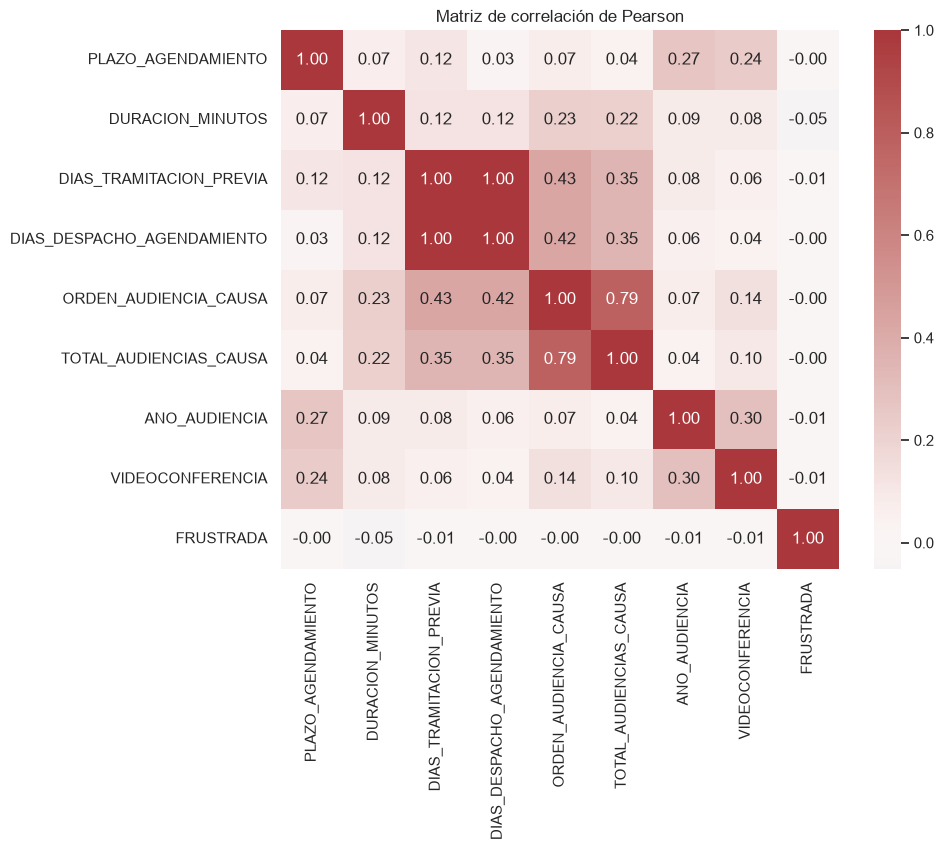

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(pearson, cmap='vlag', center=0, annot=True, fmt='.2f')
plt.title('Matriz de correlación de Pearson')
plt.show()

**Por qué el heatmap:** deja ver de un vistazo los bloques de variables relacionadas entre sí.
**Qué mirar:**
- `DIAS_TRAMITACION_PREVIA` y `DIAS_DESPACHO_AGENDAMIENTO` muestran una correlación moderada con la espera (Spearman cercano a 0,5 y 0,3), no casi perfecta, porque incluyen otros tramos del proceso. Aun así se **construyen con las mismas fechas** que el plazo, así que son fuga de información y no deben entrar a un modelo que lo prediga.
- `VIDEOCONFERENCIA` y `ANO_AUDIENCIA` se parecen entre sí porque la modalidad remota solo existe desde 2020 (el notebook 01 imputó `False` antes de esa fecha). Esa relación es en parte artificial.

### Pregunta crítica
¿Una variable con baja correlación lineal debería descartarse? **No.** Puede haber una relación no lineal, una interacción, o una asociación que solo aparece dentro de ciertos grupos (tribunal, materia, época). Eso se revisa en las secciones siguientes.

## 7. Numérica vs categórica: ¿cambia la espera según el grupo?
**Por qué:** es la sección más importante para la pregunta P1. Los tribunales y las materias son los grupos con los que el estudio toma decisiones.
Primero la tabla resumen y luego boxplots, como en la clase.

In [12]:
resumen_materia = (df.groupby('MACRO_MATERIA')[Y]
                     .agg(n='count', media='mean', mediana='median', p75=lambda s: s.quantile(.75))
                     .sort_values('mediana'))
resumen_materia.round(1)

,n,media,mediana,p75
MACRO_MATERIA,,,,
Otros Procedimientos,22,22.30,14.00,39.80
Medidas Cautelares y Vulnerabilidad,207328,25.40,17.00,36.00
Ejecución y Alimentos (Cumplimiento),42711,25.30,20.00,33.00
Actos No Contenciosos y Voluntarios,7017,25.10,22.00,34.00
Litigación Contenciosa,209100,38.80,34.00,50.00


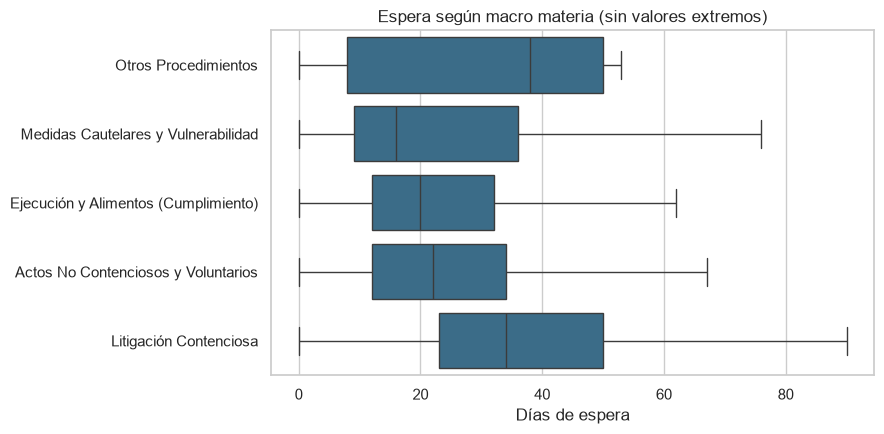

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
orden = resumen_materia.index
sns.boxplot(data=df.sample(min(150000, len(df)), random_state=1), y='MACRO_MATERIA', x=Y, order=orden, ax=ax, color=COLOR, showfliers=False)
ax.set(title='Espera según macro materia (sin valores extremos)', xlabel='Días de espera', ylabel='')
plt.tight_layout(); plt.show()

**Por qué boxplot por materia:** compara la mediana, el rango intercuartílico y la dispersión de cada materia en un solo gráfico. Ocultamos los puntos extremos (`showfliers=False`) porque ya los revisamos en la sección 3 y ensucian la comparación.

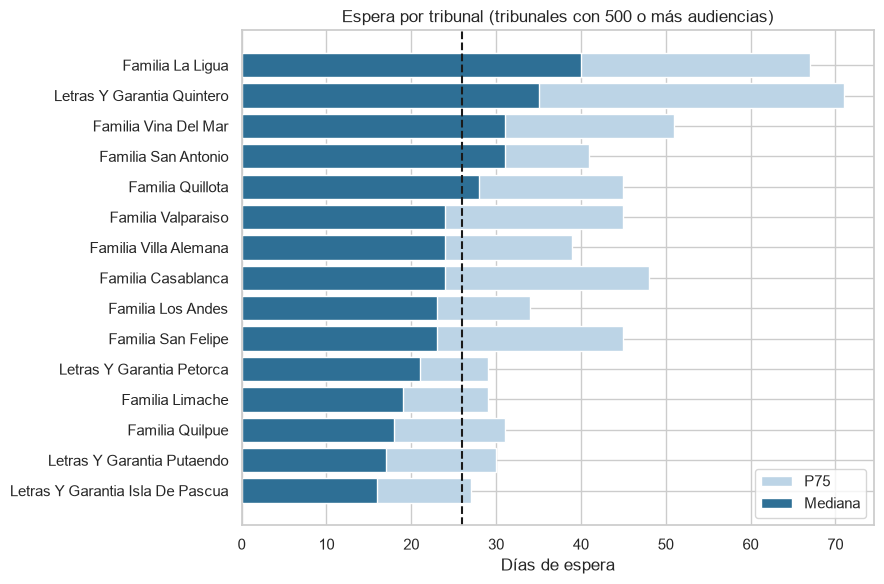

,n,mediana,p75
TRIBUNAL_CORTO,,,
Letras Y Garantia Isla De Pascua,4979,16.00,27.00
Letras Y Garantia Putaendo,5100,17.00,30.00
Familia Quilpue,33628,18.00,31.00
Familia Limache,19537,19.00,29.00
Letras Y Garantia Petorca,3602,21.00,29.00
Familia San Felipe,27497,23.00,45.00
Familia Los Andes,41901,23.00,34.00
Familia Casablanca,19641,24.00,48.00
Familia Villa Alemana,38356,24.00,39.00


In [14]:
# Espera por tribunal: mediana y P75 en barras horizontales
t = (df.groupby('TRIBUNAL_CORTO')[Y]
       .agg(n='size', mediana='median', p75=lambda s: s.quantile(.75))
       .query('n >= 500').sort_values('mediana'))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(t.index, t['p75'], color='#BCD4E6', label='P75')
ax.barh(t.index, t['mediana'], color=COLOR, label='Mediana')
ax.axvline(df[Y].median(), ls='--', color='k')
ax.set(title='Espera por tribunal (tribunales con 500 o más audiencias)', xlabel='Días de espera')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()
t.round(1)

**Por qué barras de mediana + P75 por tribunal:** responde directo a la meta del proyecto (comparar eficiencia entre jurisdicciones). La mediana muestra la espera típica y el P75 muestra qué tan mala es la espera de los casos lentos. Se filtran los tribunales con menos de 500 audiencias para no comparar medianas poco confiables.

n  mediana  \
EPOCA_NORMATIVA                         VIDEOCONFERENCIA                    
Emergencia Sanitaria (Ley 21.226)       False              78034    33.00   
                                        True               19615    48.00   
Pre-Pandemia (Presencial)               False             225891    22.00   
Régimen Permanente Híbrido (Ley 21.394) False             111582    30.00   
                                        True               31056    42.00   

                                                           p75  
EPOCA_NORMATIVA                         VIDEOCONFERENCIA        
Emergencia Sanitaria (Ley 21.226)       False            51.00  
                                        True             71.00  
Pre-Pandemia (Presencial)               False            33.00  
Régimen Permanente Híbrido (Ley 21.394) False            51.00  
                                        True             65.00

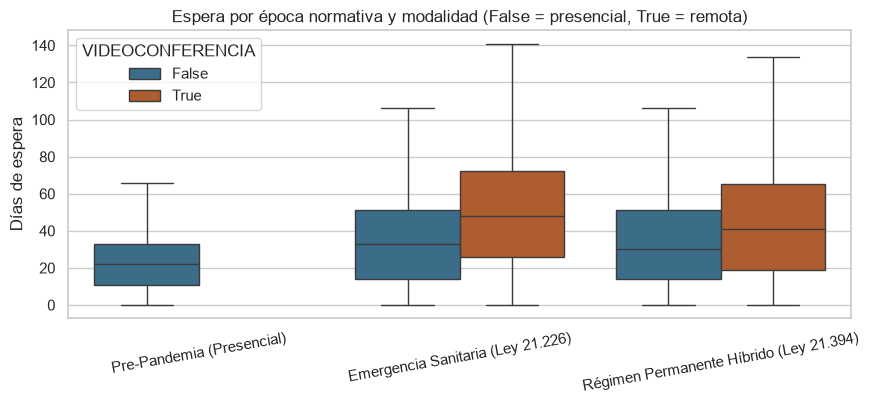

In [15]:
# Espera según época normativa y modalidad
por_epoca = (df.groupby(['EPOCA_NORMATIVA', 'VIDEOCONFERENCIA'])[Y]
               .agg(n='size', mediana='median', p75=lambda s: s.quantile(.75)))
display(por_epoca.round(1))

orden_ep = ['Pre-Pandemia (Presencial)', 'Emergencia Sanitaria (Ley 21.226)', 'Régimen Permanente Híbrido (Ley 21.394)']
plt.figure(figsize=(9, 4.2))
sns.boxplot(data=df.sample(min(150000, len(df)), random_state=2), x='EPOCA_NORMATIVA', y=Y, hue='VIDEOCONFERENCIA',
            order=orden_ep, showfliers=False, palette={False: COLOR, True: COLOR2})
plt.xticks(rotation=10); plt.xlabel('')
plt.ylabel('Días de espera'); plt.title('Espera por época normativa y modalidad (False = presencial, True = remota)')
plt.tight_layout(); plt.show()

**Por qué época × modalidad:** el notebook 01 definió tres épocas normativas. Sirve para ver si el cambio de régimen coincide con cambios en la espera, y si las audiencias remotas esperan distinto de las presenciales dentro de la misma época. **Cuidado:** esta comparación es descriptiva. Las remotas pueden ser de otro tipo de audiencia o tribunal, y eso se debe controlar antes de afirmar un efecto.

## 8. Categórica vs categórica
**Por qué:** la clase usa una tabla cruzada con heatmap. Aquí lo aplicamos a algo con sentido para el estudio: **¿qué proporción de las audiencias de cada tribunal cae en cada tramo de espera?** La mediana sola esconde si el tribunal tiene una cola de casos muy largos.

In [16]:
tabla = pd.crosstab(df['TRIBUNAL_CORTO'], df['TRAMO_AGENDAMIENTO'], normalize='index') * 100
tabla = tabla.loc[df['TRIBUNAL_CORTO'].value_counts().index]   # ordenado por volumen
tabla.round(1)

TRAMO_AGENDAMIENTO,1. Inmediato (0 días),2. Rápido (1-15 días),3. Estándar Legal (16-30 días),4. Demora Moderada (31-60 días),5. Congestión Severa (61-120 días),6. Cuello de Botella Crítico (> 120 días)
TRIBUNAL_CORTO,,,,,,
Familia Vina Del Mar,0.50,24.00,25.40,35.00,13.30,1.90
Familia Valparaiso,2.80,31.30,23.70,29.50,12.00,0.60
Familia Los Andes,0.40,32.50,36.10,25.10,5.60,0.20
Familia Quillota,10.20,21.60,22.40,32.40,12.00,1.20
Familia Villa Alemana,0.90,33.60,26.50,31.10,6.70,1.00
Familia Quilpue,2.20,42.50,29.10,18.60,6.90,0.60
Familia San Felipe,1.20,40.80,17.20,30.80,10.10,0.00
Familia San Antonio,0.30,19.60,27.10,51.50,1.50,0.00
Familia Casablanca,0.30,35.50,23.10,25.00,15.70,0.40


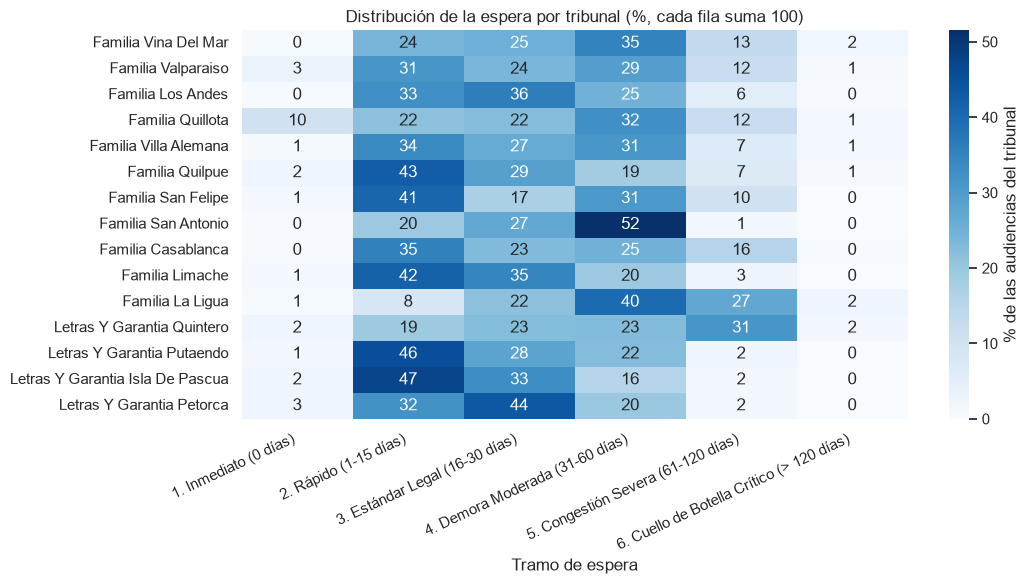

In [17]:
plt.figure(figsize=(11, 6))
sns.heatmap(tabla, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% de las audiencias del tribunal'})
plt.title('Distribución de la espera por tribunal (%, cada fila suma 100)')
plt.xlabel('Tramo de espera'); plt.ylabel('')
plt.xticks(rotation=25, ha='right')
plt.tight_layout(); plt.show()

**Por qué este heatmap:** cada fila es un tribunal y las columnas son tramos de espera ordenados (de inmediato a cuello de botella). Un tribunal con color intenso a la derecha es un tribunal con casos que superan los 60 o 120 días, aunque su mediana parezca aceptable.

## 9. EDA multivariado: agregar dimensiones a una misma relación
**Por qué:** la clase usa color y paneles para ver si una relación cambia con una tercera variable. En este contexto el equivalente natural no es un scatter (los datos son plazos y categorías, no dos variables continuas), sino **líneas por grupo a lo largo del tiempo**: si la espera de cada materia evoluciona igual o distinto.

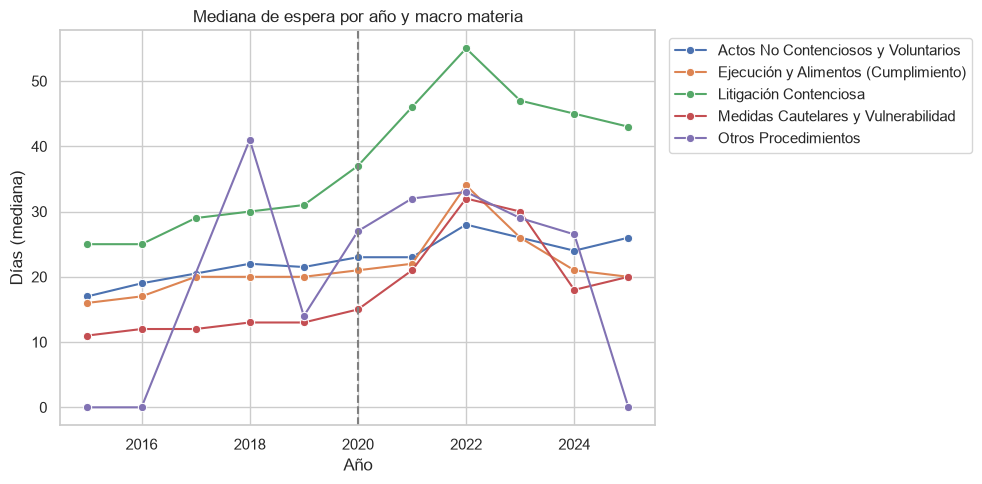

In [18]:
anual_mat = (df.groupby(['ANO_AUDIENCIA', 'MACRO_MATERIA'])[Y].median().reset_index())
plt.figure(figsize=(10, 5))
sns.lineplot(data=anual_mat, x='ANO_AUDIENCIA', y=Y, hue='MACRO_MATERIA', marker='o')
plt.axvline(2020, ls='--', color='gray')
plt.title('Mediana de espera por año y macro materia')
plt.xlabel('Año'); plt.ylabel('Días (mediana)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title='')
plt.tight_layout(); plt.show()

**Por qué:** si todas las líneas suben y bajan juntas, el cambio es del sistema (por ejemplo la pandemia). Si solo una materia se separa, el problema es específico de esa materia. Esto decide si un modelo necesita un efecto "materia × año" y no solo efectos separados.

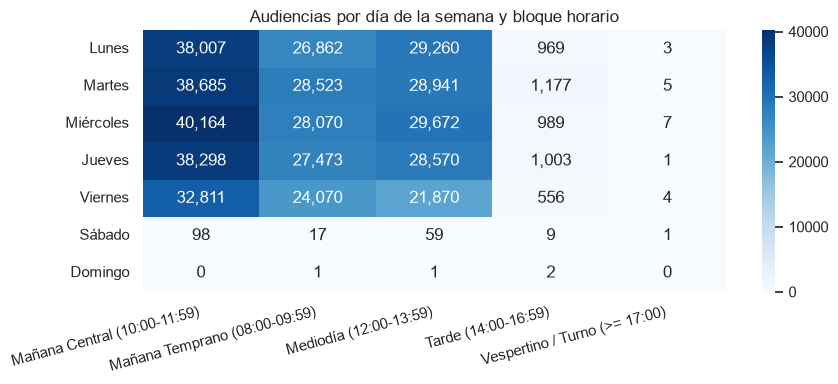

In [19]:
# Calendario: ¿en qué día y bloque se agendan más audiencias y cuánto duran?
dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
carga = pd.crosstab(df['DIA_SEMANA_AUDIENCIA'], df['BLOQUE_HORARIO']).reindex([d for d in dias if d in df['DIA_SEMANA_AUDIENCIA'].unique()])
plt.figure(figsize=(9, 4))
sns.heatmap(carga, annot=True, fmt=',d', cmap='Blues')
plt.title('Audiencias por día de la semana y bloque horario')
plt.xlabel(''); plt.ylabel('')
plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.show()

**Por qué:** responde la pregunta P5 (carga de agenda) con una sola figura. Muestra los bloques saturados y los vacíos, útil para proponer horarios de reunión con clientes y para anticipar dónde chocarán las agendas del estudio.

> **Gráficos de la clase que no usamos y por qué**
> - `lmplot` de descuento vs monto por segmento: la espera no tiene una variable continua que explique su evolución dentro de cada grupo. Una recta por grupo no aporta aquí. Lo reemplazamos por líneas por año y materia.
> - Scatter con color y símbolo (ingreso, segmento, canal): todas las variables de contexto de este dataset son categóricas. Un scatter con tres categorías superpuestas, sobre 466 mil filas, no se lee.

## 10. Componente temporal T
**Por qué:** el contexto temporal de los datos judiciales importa mucho (pandemia, cambios de ley). Graficamos **dos paneles alineados**: el volumen de audiencias y la espera mediana mes a mes. Usamos dos paneles y no dos ejes, para no mezclar escalas distintas en el mismo gráfico.

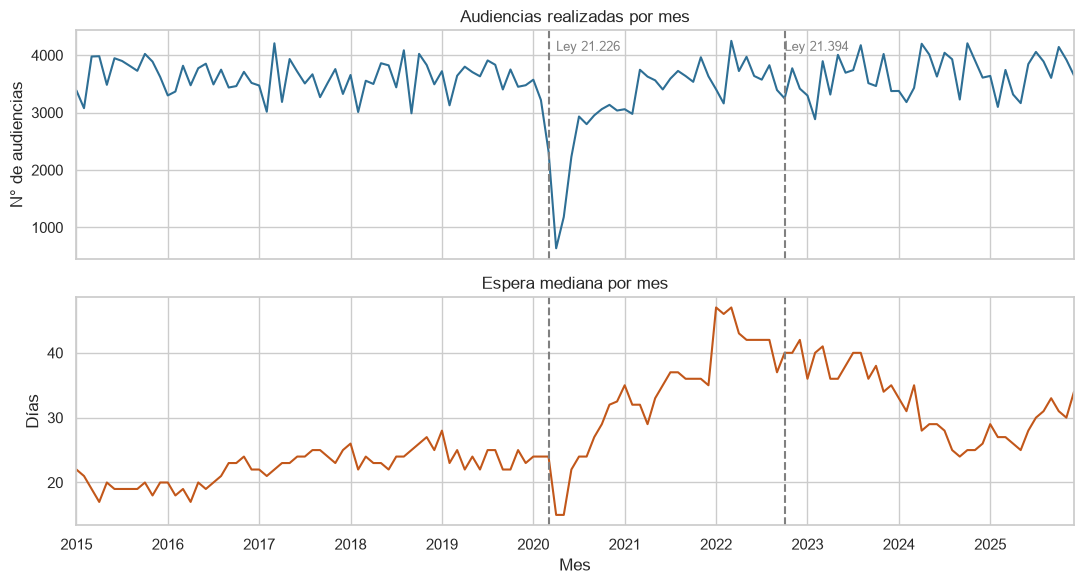

,median,count
FECHA_AUDIENCIA,,
2015-01-01,22.00,3386
2015-02-01,21.00,3077
2015-03-01,19.00,3977
2015-04-01,17.00,3982
2015-05-01,20.00,3484


In [20]:
mensual = (df.set_index('FECHA_AUDIENCIA')
             .resample('MS')[Y].agg(['median', 'count']))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
mensual['count'].plot(ax=axes[0], color=COLOR)
axes[0].set(title='Audiencias realizadas por mes', ylabel='N° de audiencias')
mensual['median'].plot(ax=axes[1], color=COLOR2)
axes[1].set(title='Espera mediana por mes', ylabel='Días', xlabel='Mes')
for ax in axes:
    ax.axvline(pd.Timestamp('2020-03-18'), ls='--', color='gray')
    ax.axvline(pd.Timestamp('2022-10-01'), ls='--', color='gray')
axes[0].text(pd.Timestamp('2020-04-01'), axes[0].get_ylim()[1] * .92, 'Ley 21.226', color='gray', fontsize=9)
axes[0].text(pd.Timestamp('2022-10-20'), axes[0].get_ylim()[1] * .92, 'Ley 21.394', color='gray', fontsize=9)
plt.tight_layout(); plt.show()
mensual.head()

**Por qué las dos líneas verticales:** son los dos hitos normativos que definió el notebook 01 para `EPOCA_NORMATIVA`. Permiten ver si los cambios de nivel coinciden con los cambios de régimen.
**Qué mirar:** la caída de volumen del 2020 (suspensión de audiencias) y si la espera sube **después** de la caída, lo que indicaría acumulación de causas.

## 11. De gráfico a hallazgo
Un buen hallazgo tiene cuatro piezas: **observación, evidencia, interpretación y siguiente pregunta**. La tabla siguiente reúne la evidencia con los datos actuales, para redactar los hallazgos sin copiar números a mano.

In [21]:
hall_t = (df.groupby('TRIBUNAL_CORTO')[Y].agg(n='count', mediana='median', p75=lambda s: s.quantile(.75))
            .query('n >= 500').sort_values('mediana'))
hall_e = df.groupby('EPOCA_NORMATIVA')[Y].agg(n='count', mediana='median', p75=lambda s: s.quantile(.75))

print('Tribunal más rápido:', hall_t.index[0], f"({hall_t['mediana'].iloc[0]:.0f} días de mediana)")
print('Tribunal más lento :', hall_t.index[-1], f"({hall_t['mediana'].iloc[-1]:.0f} días de mediana)")
print(f"Razón lento / rápido: {hall_t['mediana'].iloc[-1] / max(hall_t['mediana'].iloc[0], 1):.1f}x")
print()
hall_e.round(1)

Tribunal más rápido: Letras Y Garantia Isla De Pascua (16 días de mediana)
Tribunal más lento : Familia La Ligua (40 días de mediana)
Razón lento / rápido: 2.5x



,n,mediana,p75
EPOCA_NORMATIVA,,,
Emergencia Sanitaria (Ley 21.226),97649,35.00,55.00
Pre-Pandemia (Presencial),225891,22.00,33.00
Régimen Permanente Híbrido (Ley 21.394),142638,33.00,54.00


### Plantilla de redacción (completar con el equipo)
- **Observación:** *(ej. la espera mediana difiere mucho entre tribunales)*
- **Evidencia:** *(gráfico de la sección 7 y tabla anterior)*
- **Interpretación:** *(ej. hay diferencias de capacidad de agenda entre jurisdicciones, no solo de volumen)*
- **Siguiente pregunta:** *(¿la diferencia persiste al comparar dentro de la misma materia y tipo de audiencia?)*

## 12. Checklist antes de modelar
- ¿Entiendo la unidad de análisis? **Sí**, una audiencia; las filas de una misma causa no son independientes.
- ¿Conozco la forma de Y? **Sí**, con cola larga a la derecha. Se trabaja con medianas y percentiles.
- ¿Detecté observaciones atípicas y las interpreté? **Sí**, sección 3.
- ¿Detecté variables con fuga? **Sí**, `DIAS_TRAMITACION_PREVIA` y `DIAS_DESPACHO_AGENDAMIENTO` (sección 6).
- ¿Comparé grupos relevantes? **Sí**, tribunal, materia, época y modalidad.
- ¿Revisé el contexto temporal? **Sí**, sección 10.
- **Pendiente:** controlar las comparaciones por tipo de audiencia y materia, y elegir la validación temporal.

## 13. Ideas de modelos predictivos

Todas las propuestas usan **validación temporal** (entrenar con años antiguos y evaluar con los más recientes, por ejemplo entrenar 2015–2023 y probar 2024–2025) y **separación por causa** (`ID_CAUSA_RIT`), porque las filas de una causa no son independientes. Un modelo siempre se compara contra una **línea base simple** (por ejemplo, la mediana histórica por tribunal y tipo de audiencia).

| # | Qué predice | Tipo de problema | Datos a utilizar | Modelo / estrategia | Software |
|---|-------------|------------------|------------------|---------------------|----------|
| **A** | **Espera** hasta la audiencia (`PLAZO_AGENDAMIENTO`), con un rango (P25 a P75) | Regresión, idealmente por cuantiles | Tribunal, macro materia, tipo de audiencia, orden de la audiencia en la causa, mes, día de la semana, época, modalidad, **carga del tribunal el mes anterior** (variable nueva a construir) | Línea base: mediana por tribunal y materia. Luego gradient boosting con pérdida de cuantiles (LightGBM o `HistGradientBoostingRegressor`). Métricas: MAE y cobertura del rango | Python, pandas, scikit-learn, LightGBM, SHAP para explicar |
| **B** | **Audiencia frustrada** (`FLG_AUDIENCIA_FRUSTRADA`) | Clasificación desbalanceada | Tipo de audiencia, materia, tribunal, bloque horario, día, plazo, orden, modalidad, época | Regresión logística como base y gradient boosting después, con peso por clase. Métricas: PR-AUC y recall de la clase positiva (no exactitud) | scikit-learn, imbalanced-learn, LightGBM |
| **C** | **N° de audiencias por causa** (`TOTAL_AUDIENCIAS_CAUSA`) | Regresión de conteo | Datos de la **primera audiencia**: tribunal, materia, tipo, año, plazo inicial | Regresión de Poisson o binomial negativa como base y gradient boosting después. **Ojo:** las causas recientes están incompletas (censura a la derecha); se deben excluir las causas de los últimos meses | statsmodels (GLM), scikit-learn |
| **D** | **Carga mensual** de audiencias por tribunal | Series de tiempo | Conteo mensual por tribunal, época normativa, feriados de Chile | ETS o SARIMA por tribunal como base. Alternativa global con LightGBM y rezagos. Evaluar con ventanas móviles | statsmodels, sktime o Prophet, pandas |
| **E** | **Duración** de la audiencia (`DURACION_MINUTOS`) | Regresión por cuantiles | Tipo de audiencia, materia, tribunal, bloque horario, orden, modalidad | Gradient boosting con cuantiles. Sirve para estimar horas facturables y reservar bloques | scikit-learn, LightGBM |

### Estrategia recomendada
1. Empezar por **A** (espera). Es la que más valor da al estudio y la que conecta con el producto "Radar de Espera" del proyecto.
2. Construir **variables nuevas** que hoy no existen: carga del tribunal en el mes anterior, mediana móvil de espera por tribunal, y marcas de feriados.
3. Excluir variables con **fuga**: para A no usar `DIAS_TRAMITACION_PREVIA`, `DIAS_DESPACHO_AGENDAMIENTO` ni `TRAMO_AGENDAMIENTO` (se derivan del plazo). Para B no usar `DURACION_MINUTOS` ni `TRAMO_DURACION`.
4. Reportar siempre el **error contra la línea base** y el error **por tribunal**. Un modelo que mejora el promedio pero falla en los tribunales pequeños no sirve para el estudio.
5. Publicar el resultado en la app Streamlit que ya existe en `src/App/`.

> **Limitación de los datos:** no tienen información del contenido de la causa (monto, número de partes, tipo de conflicto detallado), que seguramente explica parte de la duración y del número de audiencias. Los modelos capturan **contexto del tribunal y del calendario**, no la complejidad del caso.